In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/angegusenga/telecom-dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv


## Introduction

Customer churn is the situation where customers stop using the services of a company. Customer churn analysis helps telecom companies understand factors associated with customers leaving their services.

The objective of this lab is to analyze the Telco Customer Churn dataset using Python in a Kaggle Notebook. The analysis involves loading the dataset, examining its structure, performing data preprocessing, and exploring customer churn in relation to demographic characteristics, phone services, contracts, and payment methods.

Pandas will be used for data manipulation, while Matplotlib and Seaborn will be used for data visualization. The findings will be interpreted to identify patterns associated with customer churn.

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


Explanation:

pandas handles tabular data.

numpy provides numerical operations.

matplotlib creates charts.

seaborn creates statistical visualizations.

In [3]:

from pathlib import Path

csv_files = list(
    Path("/kaggle/input").rglob(
        "WA_Fn-UseC_-Telco-Customer-Churn.csv"
    )
)

df = pd.read_csv(csv_files[0])

print("Dataset loaded successfully!")


Dataset loaded successfully!


The Telco Customer Churn dataset has been successfully loaded into the Kaggle Notebook using the Pandas library. The dataset is now stored in a DataFrame named df and is ready for inspection and analysis.

In [4]:
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


The output displays the first five customer records in the dataset. It shows various customer attributes such as customer ID, gender, senior citizen status, subscription services, payment information, and churn status. The Churn attribute contains Yes or No values indicating whether a customer has left the company.

In [5]:
df.tail()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


The output displays the last five records of the dataset. This confirms that the dataset contains customer records throughout the file and allows us to inspect the final observations.

In [6]:
print("Dataset shape:", df.shape)

print("Number of customers:", df.shape[0])
print("Number of attributes:", df.shape[1])

Dataset shape: (7043, 21)
Number of customers: 7043
Number of attributes: 21


The dataset consists of 7,043 customer records and 21 attributes. Each row represents a customer, while each column describes a characteristic of that customer or their telecom service.

## Data Preprocessing

### Converting Churn Values from Yes/No to 1/0

In [7]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print(df['Churn'].value_counts().sort_index())


Churn
0    5174
1    1869
Name: count, dtype: int64


The Churn attribute was successfully converted from categorical values (Yes and No) into numerical values (1 and 0). A value of 1 represents customers who have left the telecom company, while 0 represents customers who remained. The results indicate that 5,174 customers did not churn, whereas 1,869 customers churned. This transformation makes the data easier to analyze numerically.

### Checking and Correcting Attribute Data Types

In [8]:
print(df.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                 int64
dtype: object


In [9]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'], errors='coerce'
)

categorical_columns = df.select_dtypes(
    include=['object']
).columns.drop('customerID')

df[categorical_columns] = df[categorical_columns].astype('category')

print(df.dtypes)

customerID            object
gender              category
SeniorCitizen          int64
Partner             category
Dependents          category
tenure                 int64
PhoneService        category
MultipleLines       category
InternetService     category
OnlineSecurity      category
OnlineBackup        category
DeviceProtection    category
TechSupport         category
StreamingTV         category
StreamingMovies     category
Contract            category
PaperlessBilling    category
PaymentMethod       category
MonthlyCharges       float64
TotalCharges         float64
Churn                  int64
dtype: object


The data types of all attributes were examined using the Pandas library. The TotalCharges attribute was initially stored as an object despite representing numerical values. It was converted to float64 to support numerical analysis. Text-based categorical attributes, such as gender, Contract and PaymentMethod, were converted to category data types. The customerID attribute was retained as a string because it serves as a unique customer identifier. These changes ensure the attributes have appropriate data types for analysis.

### Identifying and Handling Missing Values

In [10]:
print(df.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [11]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

TotalCharges    11
dtype: int64


Missing values were checked using the isnull() function. The results show that the TotalCharges attribute contains 11 missing values, while the other attributes have no missing values. These missing values were detected after converting TotalCharges into a numerical data type. They must be handled to ensure accurate analysis.

In [12]:
df = df.dropna(subset=['TotalCharges']).copy()

print("Dataset shape after cleaning:", df.shape)

print("Remaining missing values:", df.isnull().sum().sum())

Dataset shape after cleaning: (7032, 21)
Remaining missing values: 0


The 11 customer records containing missing TotalCharges values were removed using the dropna() function. As a result, the number of customer records decreased from 7,043 to 7,032, while the number of attributes remained 21. A final check confirmed that no missing values remain in the dataset. Therefore, the cleaned dataset is ready for exploratory data analysis.

In [13]:
display(df.head())

df.info()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   customerID        7032 non-null   object  
 1   gender            7032 non-null   category
 2   SeniorCitizen     7032 non-null   int64   
 3   Partner           7032 non-null   category
 4   Dependents        7032 non-null   category
 5   tenure            7032 non-null   int64   
 6   PhoneService      7032 non-null   category
 7   MultipleLines     7032 non-null   category
 8   InternetService   7032 non-null   category
 9   OnlineSecurity    7032 non-null   category
 10  OnlineBackup      7032 non-null   category
 11  DeviceProtection  7032 non-null   category
 12  TechSupport       7032 non-null   category
 13  StreamingTV       7032 non-null   category
 14  StreamingMovies   7032 non-null   category
 15  Contract          7032 non-null   category
 16  PaperlessBilling  7032 non-nu

Data Preprocessing Summary

Data preprocessing was successfully completed by converting the Churn attribute from Yes/No to 1/0, correcting attribute data types, identifying missing values, and removing incomplete customer records. The final cleaned dataset contains 7,032 records and 21 attributes. It is now suitable for further analysis.

## Exploratory Data Analysis (EDA)

### 1. Demographic Analysis

This section examines how customer demographic characteristics, including gender, senior citizen status, partner status, and dependents, are associated with customer churn.

In [14]:
def explore_churn(column, title, labels=None):

    table = pd.crosstab(
        df[column], df['Churn']
    ).reindex(columns=[0, 1], fill_value=0)

    table.columns = ['Stayed', 'Churned']

    table['Total'] = table['Stayed'] + table['Churned']
    table['Churn Rate (%)'] = (
        table['Churned'] / table['Total'] * 100
    ).round(2)

    if labels is not None:
        table = table.rename(index=labels)

    display(table)

    ax = table['Churn Rate (%)'].plot(
        kind='bar',
        figsize=(8, 4),
        color='steelblue',
        rot=0
    )

    plt.title(title)
    plt.xlabel(column)
    plt.ylabel('Churn Rate (%)')
    plt.ylim(0, 55)

    for bar in ax.patches:
        height = bar.get_height()
        ax.annotate(
            f'{height:.1f}%',
            (bar.get_x() + bar.get_width() / 2, height),
            ha='center',
            va='bottom'
        )

    plt.tight_layout()
    plt.show()


,Stayed,Churned,Total,Churn Rate (%)
gender,,,,
Female,2544,939,3483,26.96
Male,2619,930,3549,26.20


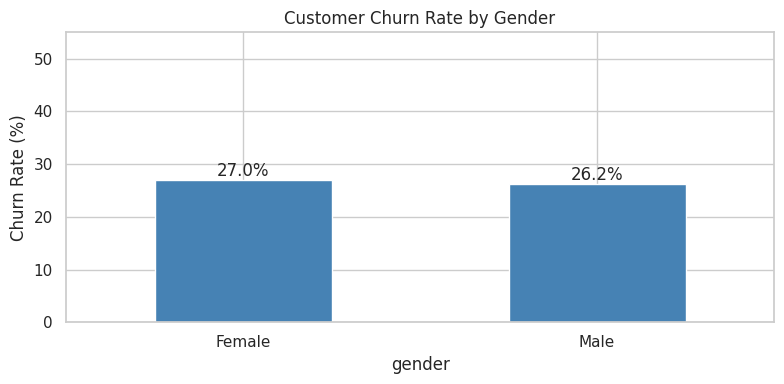

In [15]:
explore_churn('gender', 'Customer Churn Rate by Gender')

Interpretation: Gender and Churn

The analysis shows that female customers have a churn rate of 26.96%, while male customers have a churn rate of 26.20%. The difference between the two groups is very small, approximately 0.76 percentage points.

This suggests that gender does not show a strong association with customer churn in this dataset. Both male and female customers have nearly equal chances of leaving the telecom company.

,Stayed,Churned,Total,Churn Rate (%)
SeniorCitizen,,,,
Not Senior,4497,1393,5890,23.65
Senior,666,476,1142,41.68


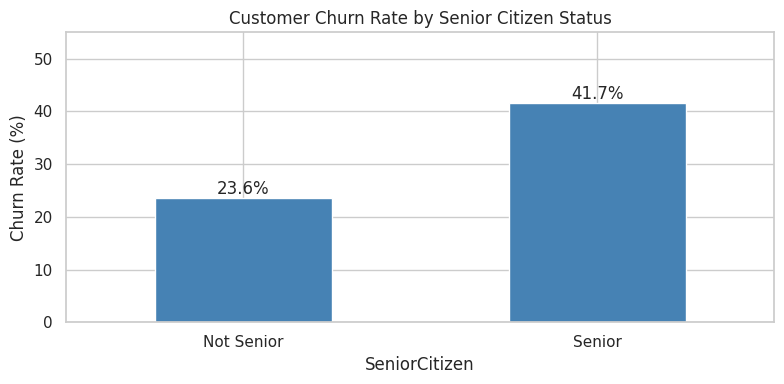

In [16]:
explore_churn(
    'SeniorCitizen',
    'Customer Churn Rate by Senior Citizen Status',
    labels={0: 'Not Senior', 1: 'Senior'}
)

Interpretation: SeniorCitizen and Churn

The results indicate that senior citizen customers have a higher churn rate of 41.68%, compared to 23.65% for non-senior citizen customers.

This means that senior citizens are more likely to leave the telecom company than other customers in this dataset. The company could investigate the needs and challenges of senior citizens to identify opportunities for improving customer retention.

,Stayed,Churned,Total,Churn Rate (%)
Partner,,,,
No,2439,1200,3639,32.98
Yes,2724,669,3393,19.72


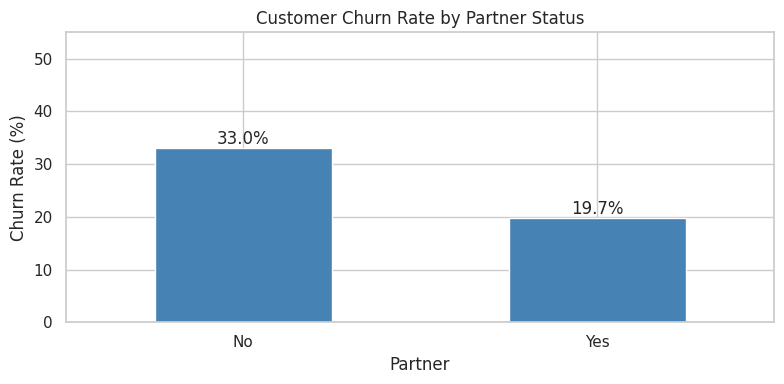

In [17]:
explore_churn('Partner', 'Customer Churn Rate by Partner Status')

Interpretation: Partner and Churn

The analysis shows that customers without partners have a churn rate of 32.98%, whereas customers with partners have a lower churn rate of 19.72%.

This suggests that customers without partners are more likely to discontinue telecom services. Partner status is therefore associated with differences in customer churn, although the analysis does not establish that having a partner directly reduces churn.

,Stayed,Churned,Total,Churn Rate (%)
Dependents,,,,
No,3390,1543,4933,31.28
Yes,1773,326,2099,15.53


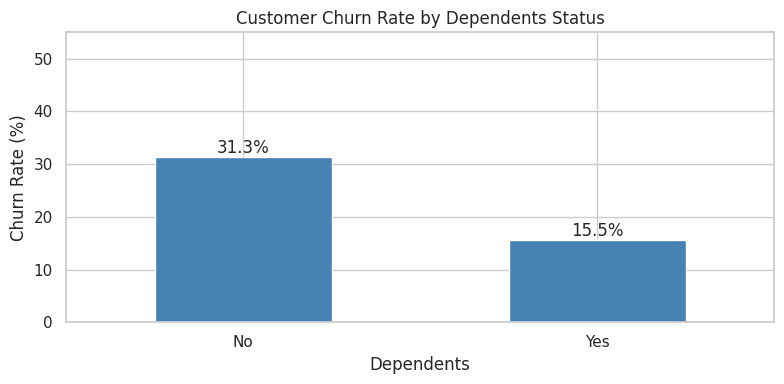

In [18]:
explore_churn(
    'Dependents',
    'Customer Churn Rate by Dependents Status'
)

Interpretation: Dependents and Churn

Customers without dependents have a churn rate of 31.28%, while customers with dependents have a churn rate of 15.53%.

The results indicate that customers without dependents are more likely to leave the telecom company. Having dependents is associated with lower customer churn, potentially reflecting differences in customer needs or subscription patterns.

### Demographic Analysis Summary

The demographic analysis revealed the following findings:

1. **Gender:** Male and female customers have nearly equal churn rates, indicating a weak relationship between gender and churn.

2. **SeniorCitizen:** Senior citizens have a considerably higher churn rate than non-senior citizens.

3. **Partner:** Customers without partners have a higher churn rate than those with partners.

4. **Dependents:** Customers without dependents are more likely to churn than customers with dependents.

**Conclusion:** Senior citizen status, partner status, and dependents show noticeable associations with customer churn, while gender shows little difference. These findings may help the telecom company identify customer groups that need additional retention efforts.

### 2. Service Analysis

#### PhoneService Against Churn

This analysis examines the relationship between phone service subscription and customer churn.

,Stayed,Churned,Total,Churn Rate (%)
PhoneService,,,,
No,510,170,680,25.00
Yes,4653,1699,6352,26.75


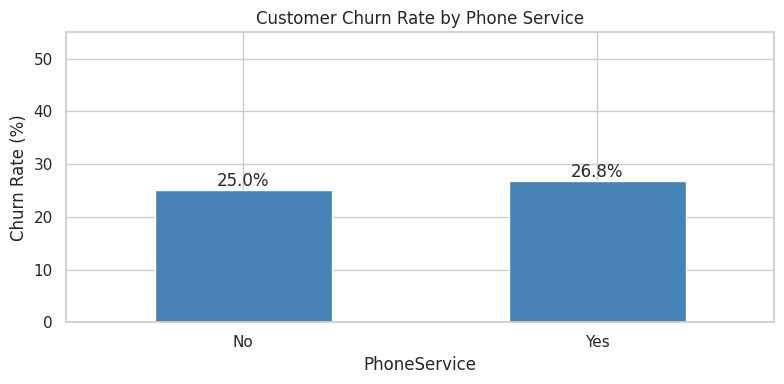

In [19]:
explore_churn(
    'PhoneService',
    'Customer Churn Rate by Phone Service'
)

Interpretation: PhoneService and Churn

The results show that customers with phone service have a churn rate of 26.75%, compared to 25.00% for customers without phone service.

The difference between these two groups is only 1.75 percentage points. This suggests that phone service subscription has a relatively weak association with customer churn. Other factors, such as contract type or payment method, may show stronger differences.

### 3. Payment Analysis

#### Contract Against Churn

This analysis examines how the type of contract selected by customers is associated with their likelihood of leaving the telecom company.

,Stayed,Churned,Total,Churn Rate (%)
Contract,,,,
Month-to-month,2220,1655,3875,42.71
One year,1306,166,1472,11.28
Two year,1637,48,1685,2.85


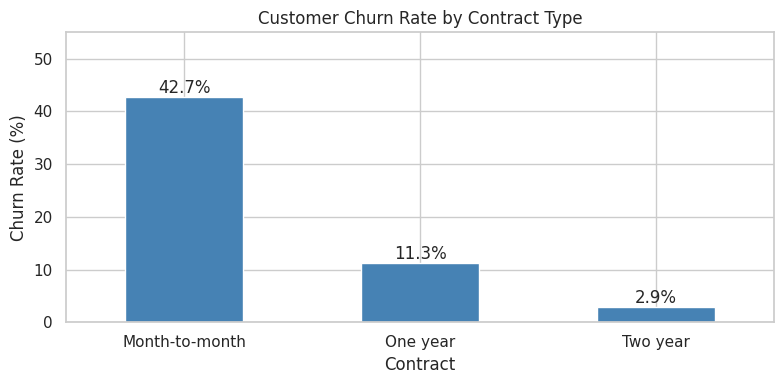

In [20]:
explore_churn(
    'Contract',
    'Customer Churn Rate by Contract Type'
)

Interpretation: Contract and Churn

The analysis indicates that customers with month-to-month contracts have the highest churn rate of 42.71%. Customers with one-year contracts have a lower churn rate of 11.28%, while those with two-year contracts have the lowest churn rate of 2.85%.

These results show a strong association between contract duration and customer churn. Customers with longer contracts are less likely to leave the company. The telecom company could investigate incentives that encourage customers to choose longer-term contracts as a possible customer retention strategy.

#### PaperlessBilling Against Churn

This analysis investigates the relationship between paperless billing and customer churn.

,Stayed,Churned,Total,Churn Rate (%)
PaperlessBilling,,,,
No,2395,469,2864,16.38
Yes,2768,1400,4168,33.59


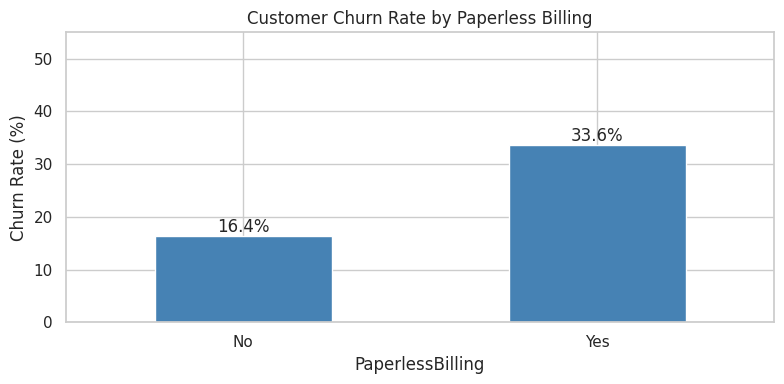

In [21]:
explore_churn(
    'PaperlessBilling',
    'Customer Churn Rate by Paperless Billing'
)

Interpretation: PaperlessBilling and Churn

The results show that customers using paperless billing have a churn rate of 33.59%, while customers who do not use paperless billing have a lower churn rate of 16.38%.

This suggests that paperless billing is associated with higher customer churn in the dataset. However, this does not necessarily mean paperless billing causes customers to leave. Further investigation is required to identify other factors associated with the difference.

#### PaymentMethod Against Churn

This analysis examines how different customer payment methods are associated with churn.

,Stayed,Churned,Total,Churn Rate (%)
PaymentMethod,,,,
Bank transfer (automatic),1284,258,1542,16.73
Credit card (automatic),1289,232,1521,15.25
Electronic check,1294,1071,2365,45.29
Mailed check,1296,308,1604,19.20


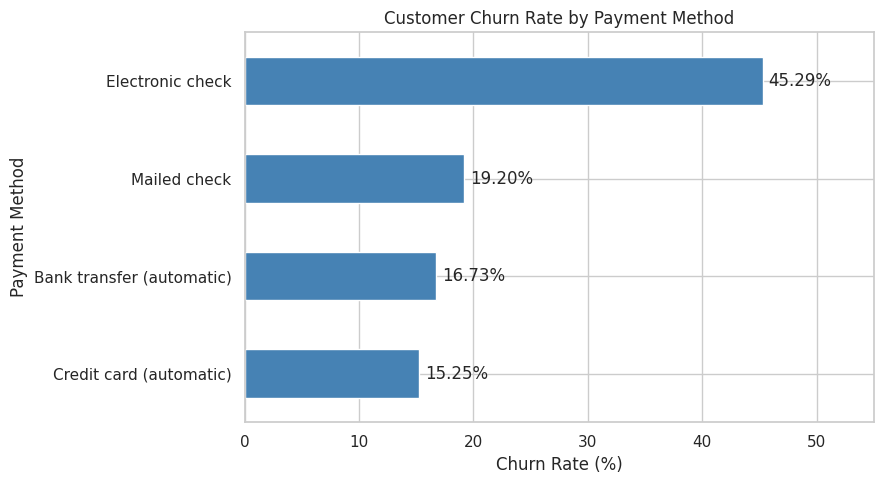

In [22]:
payment_table = pd.crosstab(
    df['PaymentMethod'],
    df['Churn']
).reindex(columns=[0, 1], fill_value=0)

payment_table.columns = ['Stayed', 'Churned']

payment_table['Total'] = (
    payment_table['Stayed'] + payment_table['Churned']
)

payment_table['Churn Rate (%)'] = (
    payment_table['Churned'] /
    payment_table['Total'] * 100
).round(2)

display(payment_table)

payment_sorted = payment_table.sort_values(
    'Churn Rate (%)'
)

ax = payment_sorted['Churn Rate (%)'].plot(
    kind='barh',
    figsize=(9, 5),
    color='steelblue'
)

plt.title('Customer Churn Rate by Payment Method')
plt.xlabel('Churn Rate (%)')
plt.ylabel('Payment Method')
plt.xlim(0, 55)

for i, rate in enumerate(payment_sorted['Churn Rate (%)']):
    plt.text(rate + 0.5, i, f'{rate:.2f}%', va='center')

plt.tight_layout()
plt.show()


Interpretation: PaymentMethod and Churn

The analysis shows that customers using electronic checks have the highest churn rate of 45.29%. Customers using mailed checks have a churn rate of 19.20%, while customers using automatic bank transfers and automatic credit card payments have churn rates of 16.73% and 15.25%, respectively.

These findings indicate that payment method is strongly associated with customer churn. Customers using electronic checks are more likely to leave the company compared to customers using other payment methods. The telecom company could investigate why electronic check users have higher churn and whether encouraging convenient automatic payment options may help improve customer retention.

## Conclusion

The objective of this lab was to analyze customer churn in a telecom company using Python. The dataset initially contained 7,043 customer records and 21 attributes. After data preprocessing, 11 records containing missing values were removed, leaving 7,032 records for analysis.

The exploratory data analysis examined demographic characteristics, phone service subscriptions, contract types, paperless billing, and payment methods.

**Key findings:**

1. **Gender:** Male and female customers have nearly equal churn rates, suggesting that gender has little association with churn.
2. **SeniorCitizen:** Senior citizens have a higher churn rate than non-senior citizens.
3. **Partner:** Customers without partners have a higher churn rate than customers with partners.
4. **Dependents:** Customers without dependents have a higher churn rate than those with dependents.
5. **PhoneService:** Customers with and without phone service have similar churn rates.
6. **Contract:** Month-to-month customers have the highest churn rate, while two-year contract customers have the lowest.
7. **PaperlessBilling:** Customers using paperless billing have higher churn rates than those who do not use it.
8. **PaymentMethod:** Customers using electronic checks have the highest churn rate compared to other payment methods.

**Overall conclusion:**

Contract type and payment method show particularly large differences in customer churn. The telecom company could investigate strategies such as encouraging longer-term contracts, improving customer support, and promoting convenient payment options to help reduce churn.

However, the analysis identifies associations rather than proving the causes of customer churn. Further investigation would be needed to confirm which strategies would effectively improve customer retention.

In [23]:
print("Number of customers:", len(df))
print("Number of attributes:", df.shape[1])
print("Missing values:", df.isnull().sum().sum())

print("\nOverall customer churn rate:")
print(f"{df['Churn'].mean() * 100:.2f}%")

Number of customers: 7032
Number of attributes: 21
Missing values: 0

Overall customer churn rate:
26.58%
